In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

In [2]:
df = pd.read_csv("/home/ved/Videos/uber.csv")

print(df.head())
print(df.shape)
print(df.info())
print(df.isnull().sum())

   Unnamed: 0                            key  fare_amount  \
0    24238194    2015-05-07 19:52:06.0000003          7.5   
1    27835199    2009-07-17 20:04:56.0000002          7.7   
2    44984355   2009-08-24 21:45:00.00000061         12.9   
3    25894730    2009-06-26 08:22:21.0000001          5.3   
4    17610152  2014-08-28 17:47:00.000000188         16.0   

           pickup_datetime  pickup_longitude  pickup_latitude  \
0  2015-05-07 19:52:06 UTC        -73.999817        40.738354   
1  2009-07-17 20:04:56 UTC        -73.994355        40.728225   
2  2009-08-24 21:45:00 UTC        -74.005043        40.740770   
3  2009-06-26 08:22:21 UTC        -73.976124        40.790844   
4  2014-08-28 17:47:00 UTC        -73.925023        40.744085   

   dropoff_longitude  dropoff_latitude  passenger_count  
0         -73.999512         40.723217                1  
1         -73.994710         40.750325                1  
2         -73.962565         40.772647                1  
3         

In [3]:
# Remove unnecessary columns
df.drop(['Unnamed: 0', 'key'], axis=1, inplace=True, errors='ignore')

# Remove missing values
df.dropna(inplace=True)

# Remove duplicate records
df.drop_duplicates(inplace=True)

# Convert pickup_datetime into datetime format
df['pickup_datetime'] = pd.to_datetime(df['pickup_datetime'])

# Extract useful date and time features
df['hour'] = df['pickup_datetime'].dt.hour
df['day'] = df['pickup_datetime'].dt.day
df['month'] = df['pickup_datetime'].dt.month
df['year'] = df['pickup_datetime'].dt.year

# Remove original datetime column
df.drop('pickup_datetime', axis=1, inplace=True)

print("Dataset after preprocessing:")
print(df.head())

print("\nShape:", df.shape)

Dataset after preprocessing:
   fare_amount  pickup_longitude  pickup_latitude  dropoff_longitude  \
0          7.5        -73.999817        40.738354         -73.999512   
1          7.7        -73.994355        40.728225         -73.994710   
2         12.9        -74.005043        40.740770         -73.962565   
3          5.3        -73.976124        40.790844         -73.965316   
4         16.0        -73.925023        40.744085         -73.973082   

   dropoff_latitude  passenger_count  hour  day  month  year  
0         40.723217                1    19    7      5  2015  
1         40.750325                1    20   17      7  2009  
2         40.772647                1    21   24      8  2009  
3         40.803349                3     8   26      6  2009  
4         40.761247                5    17   28      8  2014  

Shape: (199999, 10)


Number of outliers: 17166


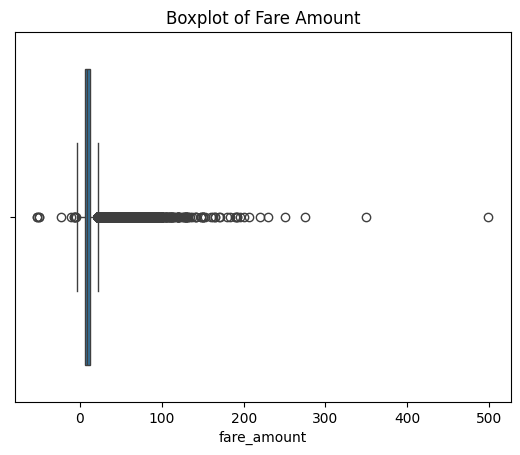

Shape after removing outliers: (182833, 10)


In [4]:
Q1 = df['fare_amount'].quantile(0.25)
Q3 = df['fare_amount'].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

# Identify outliers
outliers = df[
    (df['fare_amount'] < lower) |
    (df['fare_amount'] > upper)
]

print("Number of outliers:", len(outliers))

# Visualize outliers
sns.boxplot(x=df['fare_amount'])
plt.title("Boxplot of Fare Amount")
plt.show()

# Remove outliers
df = df[
    (df['fare_amount'] >= lower) &
    (df['fare_amount'] <= upper)
]

print("Shape after removing outliers:", df.shape)

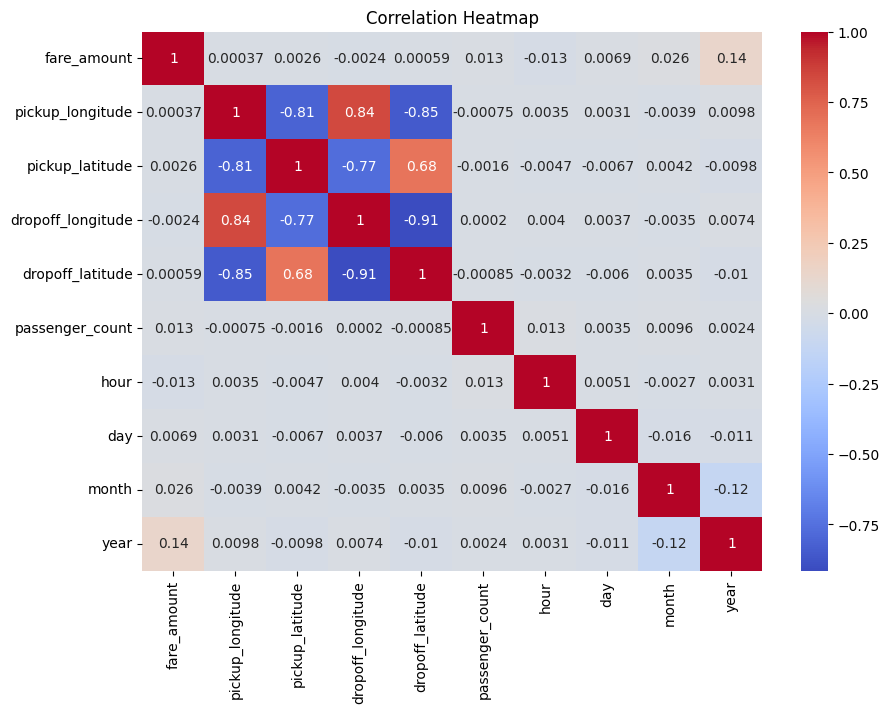


Correlation with Fare Amount:
fare_amount          1.000000
pickup_longitude     0.000367
pickup_latitude      0.002618
dropoff_longitude   -0.002413
dropoff_latitude     0.000589
passenger_count      0.012618
hour                -0.013219
day                  0.006860
month                0.026338
year                 0.135172
Name: fare_amount, dtype: float64


In [5]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    df.corr(numeric_only=True),
    annot=True,
    cmap='coolwarm'
)

plt.title("Correlation Heatmap")
plt.show()

print("\nCorrelation with Fare Amount:")
print(df.corr(numeric_only=True)['fare_amount'])

In [6]:
X = df.drop('fare_amount', axis=1)
y = df['fare_amount']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (146266, 9)
Testing data: (36567, 9)


In [ ]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("Normalized training data:")
print(X_train[:5])

In [7]:
lr = LinearRegression()

lr.fit(X_train, y_train)

y_pred_lr = lr.predict(X_test)

print("Linear Regression Results")
print("R2 Score:", r2_score(y_test, y_pred_lr))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred_lr)))
print("MAE:", mean_absolute_error(y_test, y_pred_lr))

Linear Regression Results
R2 Score: 0.021405122045019764
RMSE: 4.09228210374831
MAE: 3.2412899460928735


In [8]:
rf = RandomForestRegressor(n_estimators=50, random_state=42)

rf.fit(X_train, y_train)

y_pred_rf = rf.predict(X_test)

print("Random Forest Regression Results")
print("R2 Score:", r2_score(y_test, y_pred_rf))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred_rf)))
print("MAE:", mean_absolute_error(y_test, y_pred_rf))

Random Forest Regression Results
R2 Score: 0.7511521785765878
RMSE: 2.063626122422037
MAE: 1.4103812632258856


In [9]:
results = pd.DataFrame({
    'Model': ['Linear Regression', 'Random Forest'],
    'R2 Score': [
        r2_score(y_test, y_pred_lr),
        r2_score(y_test, y_pred_rf)
    ],
    'RMSE': [
        np.sqrt(mean_squared_error(y_test, y_pred_lr)),
        np.sqrt(mean_squared_error(y_test, y_pred_rf))
    ],
    'MAE': [
        mean_absolute_error(y_test, y_pred_lr),
        mean_absolute_error(y_test, y_pred_rf)
    ]
})

print(results)

               Model  R2 Score      RMSE       MAE
0  Linear Regression  0.021405  4.092282  3.241290
1      Random Forest  0.751152  2.063626  1.410381
